# 🚗 Analyse statistique de l'accidentologie routière en Tunisie (2002–2026)

## Contexte
Les accidents de la route sont un enjeu central pour l'**actuaire** en assurance automobile : la fréquence des sinistres et leur gravité déterminent directement le coût du risque. Le fichier étudié recense, accident par accident, près de **200 000 accidents corporels** survenus en Tunisie de janvier 2002 à septembre 2026 : localisation (gouvernorat, délégation), date et heure, type de collision, cause, autorité ayant constaté l'accident, nombre de blessés et de tués.

## Problématique
> **Où et quand les accidents de la route sont-ils les plus fréquents en Tunisie, qu'est-ce qui les rend mortels, et quelles en sont les conséquences humaines ?**

## Démarche
| Partie | Contenu | Méthodes |
|---|---|---|
| 1. Qualité des données | manquants, doublons, modalités incohérentes, cohérence des dates et des lieux | contrôles logiques |
| 2. Nettoyage | harmonisation, libellés français, variables dérivées (gravité, type de collision) | — |
| 3. Géographie | gouvernorats, délégations, concentration | statistiques descriptives |
| 4. Temporalité | années, mois, jours, heures | taux par jour, indices |
| 5. Causes et collisions | causes déclarées, usagers impliqués | taux de mortalité |
| 6. Relations statistiques | corrélations, χ², comparaisons de groupes | Spearman, χ² + V de Cramér, Mann-Whitney, Kruskal-Wallis, tailles d'effet |
| 7. Modèle multivarié | probabilité qu'un accident soit mortel | régression logistique, rapports de cotes |

**Deux notions à ne pas confondre** dans toute l'étude :
- la **fréquence** : combien d'accidents (dépend surtout du trafic et de la population) ;
- la **gravité** : la part d'accidents **mortels**, ou le nombre de tués par accident (dépend des conditions de l'accident).

## 1. Configuration

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.transforms import Bbox
from scipy.stats import chi2_contingency, kruskal, mannwhitneyu, norm, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_FILE = Path("data/accidents_routiers_tunisie.xlsx")
FIGURES, OUTPUTS = Path("figures"), Path("outputs")
for folder in (FIGURES, OUTPUTS):
    folder.mkdir(exist_ok=True)

# --- Style des graphiques -----------------------------------------------------
BLUE, ORANGE, AQUA, GREY, LIGHT_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2ab", "#dcdad4"
INK, INK_2 = "#0b0b0b", "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq", ["#ffffff", "#cde2fb", BLUE, "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f1ee", BLUE])
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7",
                     "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def pct(x: float, digits: int = 1) -> str:
    return f"{x:.{digits}f} %".replace(".", ",")


def fmt_int(x) -> str:
    return f"{int(x):,}".replace(",", " ")

### Dictionnaires de traduction

Les données sont en arabe. Pour que les graphiques et les tableaux soient lisibles par tous, les modalités sont traduites en français ; les libellés arabes d'origine restent dans la base et dans les tableaux détaillés, pour permettre la vérification.

In [2]:
GOUVERNORATS = {
    "تونس": "Tunis", "اريانة": "Ariana", "بنعروس": "Ben Arous", "منوبة": "Manouba", "نابل": "Nabeul",
    "زغوان": "Zaghouan", "بنزرت": "Bizerte", "باجة": "Béja", "جندوبة": "Jendouba", "الكاف": "Le Kef",
    "سليانة": "Siliana", "سوسة": "Sousse", "المنستير": "Monastir", "المهدية": "Mahdia", "صفاقس": "Sfax",
    "القيروان": "Kairouan", "القصرين": "Kasserine", "سيدي بوزيد": "Sidi Bouzid", "قابس": "Gabès",
    "مدنين": "Médenine", "تطاوين": "Tataouine", "قفصة": "Gafsa", "توزر": "Tozeur", "قبلي": "Kébili",
}
MOIS = {"جانفي": "Janvier", "فيفري": "Février", "مارس": "Mars", "افريل": "Avril", "ماي": "Mai", "جوان": "Juin",
        "جويلية": "Juillet", "اوت": "Août", "سبتمبر": "Septembre", "اكتوبر": "Octobre", "نوفمبر": "Novembre",
        "ديسمبر": "Décembre"}
MOIS_ORDRE = list(MOIS.values())
JOURS_ORDRE = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
JOURS_AR = {"الاثنين": "Lundi", "الثلاثاء": "Mardi", "الاربعاء": "Mercredi", "الخميس": "Jeudi",
            "الجمعة": "Vendredi", "السبت": "Samedi", "الاحد": "Dimanche"}
AUTORITE = {"شرطة": "Police (zones urbaines)", "حرس": "Garde nationale (routes et zones rurales)"}
CAUSES = {
    "السهو وعدم الانتباه": "Inattention", "شق الطريق": "Traversée de la chaussée (piéton)",
    "السرعة": "Vitesse excessive", "عدم احترام الاولوية": "Refus de priorité",
    "المداهمة": "Heurt soudain (« mdahma »)", "عدم ملازمة اليمين": "Ne pas tenir sa droite",
    "تغيير اتجاه": "Changement de direction", "المجاوزة الممنوعة": "Dépassement interdit",
    "السير الى الوراء": "Marche arrière", "عدم احترام علامة قف": "Non-respect du stop",
    "اهمال حدث": "Défaut de surveillance d'un enfant", "السير بالمعبد": "Piéton marchant sur la chaussée",
    "السير ليلا بدون انارة": "Circulation de nuit sans éclairage", "السياقة في حالة سكر": "Conduite en état d'ivresse",
    "انفلاق عجلة": "Éclatement de pneu", "محاولة صعود او نزول": "Montée/descente d'un véhicule en marche",
    "السير في اتجاه محجر": "Circulation en sens interdit", "عبور السكة": "Traversée de voie ferrée",
    "السياقة بدون رخصة": "Conduite sans permis", "فتح باب": "Ouverture de portière",
    "اختراق الضوء الاحمر": "Franchissement du feu rouge", "السياقة في حالة تعب": "Conduite en état de fatigue",
    "الانشغال اثناء السياقة": "Occupation au volant (téléphone…)", "طريق به انزلاق": "Chaussée glissante",
    "مختلفة او مجهولة": "Causes diverses ou inconnues", "خلل فني": "Défaillance technique",
    "اللعب بالطريق العام": "Jeu sur la voie publique", "التسلق بمؤخرة عربة": "Accrochage à l'arrière d'un véhicule",
    "انفصال عجلة": "Détachement de roue", "انعدام الرؤية": "Absence de visibilité",
    "عدم ترك مسافة الامان": "Distance de sécurité non respectée",
}

---
# Partie 1 — Contrôle de la qualité des données

## 2. Chargement

In [3]:
raw = pd.read_excel(DATA_FILE)
COLS = {"رقم الحادث": "identifiant", "التاريخ": "jour_du_mois", "السنة": "annee", "الشهر": "mois_ar",
        "اليوم": "jour_declare_ar", "تاريخ_كامل": "date", "الولاية": "gouvernorat_ar",
        "مكان الحادث": "lieu", "كلم": "point_km", "نوع الحادث": "type_ar", "الاسباب": "cause_ar",
        "الساعة": "heure", "قتلى": "tues", "جرحى": "blesses", "مرجع نظر": "autorite_ar",
        "المعتمدية": "delegation_ar"}
print(f"{raw.shape[0]:,} accidents × {raw.shape[1]} variables".replace(",", " "))
pd.DataFrame({"colonne d'origine": list(COLS), "nom utilisé": list(COLS.values()),
              "type": raw.dtypes.astype(str).values,
              "exemple": [raw[c].dropna().iloc[0] for c in COLS]})

199 316 accidents × 16 variables


,colonne d'origine,nom utilisé,type,exemple
0,رقم الحادث,identifiant,int64,148012
1,التاريخ,jour_du_mois,int64,1
2,السنة,annee,int64,2012
3,الشهر,mois_ar,str,جانفي
4,اليوم,jour_declare_ar,str,الأحد
5,تاريخ_كامل,date,datetime64[us],2012-01-01 00:00:00
6,الولاية,gouvernorat_ar,str,اريانة
7,مكان الحادث,lieu,str,جامع الروضة
8,كلم,point_km,int64,-1
9,نوع الحادث,type_ar,str,شاحنة بحاجز


Les colonnes sont renommées en français (`snake_case`) : le code est plus lisible et ne dépend plus de l'affichage de l'arabe.

## 3. Valeurs manquantes et doublons

In [4]:
df = raw.rename(columns=COLS)
missing = df.isna().sum()
print("Valeurs manquantes :", {k: f"{v} ({v / len(df):.1%})" for k, v in missing[missing > 0].items()} or "aucune")
print(f"Lignes strictement dupliquées          : {df.duplicated().sum()}")
print(f"Identifiants d'accident en double      : {df['identifiant'].duplicated().sum()}")

sentinels = df["point_km"].lt(0)
print(f"\nPoint kilométrique négatif (-1, -2, -3) : {sentinels.sum():,} lignes ({sentinels.mean():.1%})".replace(",", " "))
print("  valeurs :", df.loc[sentinels, "point_km"].value_counts().to_dict())

Valeurs manquantes : {'delegation_ar': '165081 (82.8%)'}
Lignes strictement dupliquées          : 0
Identifiants d'accident en double      : 0

Point kilométrique négatif (-1  -2  -3) : 141 806 lignes (71.1%)
  valeurs : {-1: 141800, -2: 5, -3: 1}


- **Délégation** : manquante pour **83 %** des accidents. Ce n'est pas un défaut ponctuel mais une limite structurelle : toute analyse par délégation ne porte que sur 17 % des accidents (on verra en section 8 qu'il s'agit essentiellement des années récentes).
- **Point kilométrique** : les valeurs négatives ne sont pas des positions mais des **codes « non renseigné »**. Ce sont donc aussi des valeurs manquantes, cachées, qui concernent 71 % des accidents (essentiellement en ville, où il n'y a pas de bornes kilométriques).
- **Aucun doublon** : chaque accident a un identifiant unique.

## 4. Modalités incohérentes

In [5]:
def normalize_ar(s: pd.Series) -> pd.Series:
    """Harmonise l'écriture arabe : espaces superflus, formes de l'alif (أ إ آ → ا)."""
    return (s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
            .str.replace("[أإآ]", "ا", regex=True))


checks = []
for col in ["gouvernorat_ar", "mois_ar", "jour_declare_ar", "autorite_ar", "cause_ar", "type_ar"]:
    raw_levels, norm_levels = df[col].nunique(), normalize_ar(df[col]).nunique()
    checks.append({"variable": col, "modalités brutes": raw_levels, "après harmonisation": norm_levels,
                   "variantes fusionnées": raw_levels - norm_levels})
print("Gouvernorats inconnus :", set(normalize_ar(df["gouvernorat_ar"])) - set(GOUVERNORATS) or "aucun (24/24)")
print("Jours déclarés bruts :", sorted(df["jour_declare_ar"].unique()))
print("Causes avec une faute de frappe :", [c for c in df["cause_ar"].unique() if "حالت" in c])
pd.DataFrame(checks)

Gouvernorats inconnus : aucun (24/24)
Jours déclarés bruts : ['الأحد', 'الإثنين', 'الإربعاء', 'الثلاثاء', 'الجمعة', 'الخميس', 'السبت']
Causes avec une faute de frappe : ['السياقة في حالت سكر']


,variable,modalités brutes,après harmonisation,variantes fusionnées
0,gouvernorat_ar,24,24,0
1,mois_ar,12,12,0
2,jour_declare_ar,7,7,0
3,autorite_ar,2,2,0
4,cause_ar,32,32,0
5,type_ar,1930,1769,161


- **Jours de la semaine** : l'orthographe est cohérente dans le fichier (7 modalités). Certains jours sont écrits avec une hamza (الأحد, الإثنين), ce qu'il faut savoir pour les rapprocher d'une liste de référence. Le vrai problème du jour de la semaine est sa **cohérence avec la date** (section 5).
- **Types d'accident** : 1 930 libellés bruts, dont 161 simples variantes d'écriture du même type (إنقلاب / انقلاب, بأخرى / باخرى). Même harmonisés, ils restent trop nombreux pour l'analyse : ils sont regroupés en **7 catégories de collision** (partie 2).
- **Causes** : une faute de frappe isolée (« حالت » au lieu de « حالة ») est corrigée.

## 5. Cohérence des dates, du jour de la semaine et des lieux

In [6]:
date = pd.to_datetime(df["date"])
computed_day = date.dt.dayofweek.map(dict(enumerate(JOURS_ORDRE)))
declared_day = normalize_ar(df["jour_declare_ar"]).map(JOURS_AR)
mismatch = declared_day != computed_day

print(f"Période couverte : {date.min():%d/%m/%Y} → {date.max():%d/%m/%Y}")
print(f"Année de la date ≠ colonne année    : {(date.dt.year != df['annee']).sum()}")
print(f"Jour du mois ≠ colonne jour du mois : {(date.dt.day != df['jour_du_mois']).sum()}")
print(f"Jour de la semaine déclaré ≠ jour calculé à partir de la date : "
      f"{mismatch.sum():,} accidents ({mismatch.mean():.1%})".replace(",", " "))
print(f"Heures hors de 0–23 : {(~df['heure'].between(0, 23)).sum()}")

last_month = date[date.dt.year == date.dt.year.max()].dt.month.max()
print(f"\nDernière année ({date.dt.year.max()}) : données jusqu'au mois {last_month} → année INCOMPLÈTE")

Période couverte : 01/01/2002 → 09/09/2026
Année de la date ≠ colonne année    : 0
Jour du mois ≠ colonne jour du mois : 1
Jour de la semaine déclaré ≠ jour calculé à partir de la date : 5 397 accidents (2.7%)
Heures hors de 0–23 : 0

Dernière année (2026) : données jusqu'au mois 9 → année INCOMPLÈTE


- Dans **2,7 %** des accidents, le jour de la semaine saisi ne correspond pas à la date. Par exemple, le 7 janvier 2012 est déclaré « mardi » alors que c'était un samedi. La date complète, cohérente avec l'année et le jour du mois, sert de référence : le jour de la semaine est **recalculé** à partir d'elle.
- **2026 est une année incomplète** (données jusqu'au 9 septembre). L'inclure dans les comparaisons annuelles ferait croire à une forte baisse des accidents. Les analyses annuelles portent donc sur les années **complètes 2002–2025**, et 2026 est signalée à part.

In [7]:
deleg = df.dropna(subset=["delegation_ar"]).assign(delegation_ar=lambda d: normalize_ar(d["delegation_ar"]))
multi = deleg.groupby("delegation_ar")["gouvernorat_ar"].nunique()
ambiguous = (deleg[deleg["delegation_ar"].isin(multi[multi > 1].index)]
             .groupby(["delegation_ar", "gouvernorat_ar"]).size().rename("accidents").reset_index())
ambiguous["gouvernorat"] = ambiguous["gouvernorat_ar"].map(GOUVERNORATS)
print(f"Délégations rattachées à plusieurs gouvernorats : {multi.gt(1).sum()} sur {len(multi)}")
ambiguous.sort_values(["delegation_ar", "accidents"], ascending=[True, False])

Délégations rattachées à plusieurs gouvernorats : 4 sur 565


,delegation_ar,gouvernorat_ar,accidents,gouvernorat
1,الزهور,تونس,82,Tunis
0,الزهور,القصرين,54,Kasserine
3,المنزه,تونس,198,Tunis
2,المنزه,اريانة,44,Ariana
5,حي الزهور,تونس,18,Tunis
6,حي الزهور,سوسة,2,Sousse
4,حي الزهور,القصرين,1,Kasserine
15,وسط المدينة,قابس,3,Gabès
12,وسط المدينة,تونس,2,Tunis
7,وسط المدينة,القصرين,1,Kasserine


Ces 4 cas ne sont pas des erreurs à corriger mais des **homonymes** : *Ezzouhour* (الزهور) est une délégation de Tunis **et** de Kasserine, et *El Menzah* (المنزه) un quartier à cheval sur Tunis et l'Ariana. *Centre-ville* (وسط المدينة) n'est pas une délégation, mais un libellé générique utilisé dans 10 gouvernorats. Conséquence pour l'analyse : une délégation est toujours identifiée par le **couple (gouvernorat, délégation)**, jamais par son seul nom.

In [8]:
victims = pd.DataFrame({
    "contrôle": ["Tués < 0", "Blessés < 0", "Accidents sans aucune victime", "Accidents avec ≥ 10 tués",
                 "Accidents avec ≥ 30 blessés"],
    "accidents": [(df.tues < 0).sum(), (df.blesses < 0).sum(), ((df.tues == 0) & (df.blesses == 0)).sum(),
                  (df.tues >= 10).sum(), (df.blesses >= 30).sum()],
})
extreme = df.loc[(df.tues >= 10) | (df.blesses >= 30),
                 ["date", "heure", "gouvernorat_ar", "type_ar", "cause_ar", "tues", "blesses"]]
extreme = extreme.assign(gouvernorat=extreme["gouvernorat_ar"].map(GOUVERNORATS)).sort_values("tues", ascending=False)
print(victims.to_string(index=False))
extreme.head(10)

                     contrôle  accidents
                     Tués < 0          0
                  Blessés < 0          0
Accidents sans aucune victime          3
     Accidents avec ≥ 10 tués          5
  Accidents avec ≥ 30 blessés         34


,date,heure,gouvernorat_ar,type_ar,cause_ar,tues,blesses,gouvernorat
159014,2019-12-01,11,باجة,انقلاب حافلة,السرعة,30,16,Béja
78507,2004-05-23,10,نابل,حافلة بحاجز,خلل فني,19,38,Nabeul
142457,2016-08-31,8,القصرين,شاحنة ثقيلة بحافلة بحاجز,خلل فني,13,42,Kasserine
159026,2019-04-27,5,سيدي بوزيد,شاحنة باخرى,انفلاق عجلة,12,19,Sidi Bouzid
181583,2023-06-23,13,صفاقس,شاحنة ثقيلة باجرة,عدم ملازمة اليمين,10,1,Sfax
144622,2016-12-28,6,بنعروس,حافلة بقطار,عبور السكة,5,54,Ben Arous
29797,2013-05-16,20,القيروان,حافلة بشاحنة ثقيلة,المجاوزة الممنوعة,5,45,Kairouan
57428,2002-07-29,8,سوسة,قطار بحافلة,اختراق الضوء الاحمر,4,76,Sousse
143112,2016-09-27,15,زغوان,انقلاب حافلة,السرعة,3,31,Zaghouan
130401,2009-04-17,7,بنعروس,انقلاب حافلة,السرعة,3,79,Ben Arous


Les nombres de victimes sont cohérents (aucune valeur négative). Seuls **3 accidents** n'ont aucune victime : le fichier recense des accidents **corporels**, ce sont donc des cas marginaux, conservés.

Les accidents à très nombreuses victimes (jusqu'à 30 tués ou 132 blessés) sont des **valeurs extrêmes réelles** : il s'agit d'accidents de car, de bus ou de transport collectif. Ils sont **conservés**, car ce sont précisément les sinistres les plus coûteux pour un assureur. Ils expliquent aussi pourquoi on privilégie les **médianes**, les **parts d'accidents mortels** et les tests **non paramétriques** plutôt que les moyennes.

---
# Partie 2 — Nettoyage et variables dérivées

Les corrections sont faites **dans le code** (et non à la main dans Excel) pour que le traitement soit traçable et reproductible. La base d'origine n'est jamais modifiée : on travaille sur une copie `acc`.

In [9]:
def collision_category(types: pd.Series) -> np.ndarray:
    """Regroupe les ~1 900 libellés de type d'accident selon l'usager le plus vulnérable impliqué."""
    t = normalize_ar(types)
    return np.select(
        [t.str.contains("مترجل"), t.str.contains("نارية"), t.str.contains("دراجة"),
         t.str.contains("انقلاب"), t.str.contains("حاجز|شجرة|عمود|حائط|جدار"), t.str.contains("سقوط راكب")],
        ["Piéton", "Deux-roues motorisé", "Vélo", "Renversement (sans tiers)", "Choc contre un obstacle",
         "Chute d'un passager"],
        "Collision entre véhicules")


acc = df.copy()
acc["date"] = pd.to_datetime(acc["date"])
acc["gouvernorat"] = normalize_ar(acc["gouvernorat_ar"]).map(GOUVERNORATS)
acc["mois"] = pd.Categorical(normalize_ar(acc["mois_ar"]).map(MOIS), categories=MOIS_ORDRE, ordered=True)
acc["jour_semaine"] = pd.Categorical(acc["date"].dt.dayofweek.map(dict(enumerate(JOURS_ORDRE))),
                                     categories=JOURS_ORDRE, ordered=True)
acc["week_end"] = acc["jour_semaine"].isin(["Samedi", "Dimanche"])
acc["tranche_horaire"] = pd.cut(acc["heure"], [-1, 5, 11, 17, 23],
                                labels=["Nuit (0h–6h)", "Matin (6h–12h)", "Après-midi (12h–18h)", "Soirée (18h–24h)"])
acc["autorite"] = acc["autorite_ar"].map(AUTORITE)
acc["cause_ar"] = normalize_ar(acc["cause_ar"]).str.replace("حالت", "حالة", regex=False)
acc["cause"] = acc["cause_ar"].map(CAUSES).fillna(acc["cause_ar"])
acc["collision"] = collision_category(acc["type_ar"])
acc["delegation_ar"] = normalize_ar(acc["delegation_ar"])
acc["point_km"] = acc["point_km"].where(acc["point_km"] >= 0)   # codes négatifs → manquant
acc["mortel"] = (acc["tues"] > 0).astype(int)
acc["victimes"] = acc["tues"] + acc["blesses"]
acc["annee_complete"] = acc["annee"] < acc["date"].dt.year.max()

print("Causes non traduites :", sorted(set(acc.loc[acc["cause"] == acc["cause_ar"], "cause_ar"])) or "aucune")
print("Gouvernorats non traduits :", acc["gouvernorat"].isna().sum())
acc["collision"].value_counts().rename("accidents").to_frame().assign(**{"%": lambda t: (t.accidents / len(acc) * 100).round(1)})

Causes non traduites : aucune
Gouvernorats non traduits : 0


,accidents,%
collision,,
Piéton,73772,37.0
Deux-roues motorisé,57923,29.1
Collision entre véhicules,37647,18.9
Renversement (sans tiers),13214,6.6
Vélo,7201,3.6
Choc contre un obstacle,6669,3.3
Chute d'un passager,2890,1.4


Variables créées :

| Variable | Définition |
|---|---|
| `mortel` | 1 si l'accident a fait au moins un tué. Définit la **gravité**, avec le nombre de tués par accident. |
| `collision` | 7 catégories construites à partir des 1 930 libellés de type, selon l'**usager le plus vulnérable** impliqué : piéton, deux-roues motorisé, vélo, renversement, obstacle, chute de passager, sinon collision entre véhicules. |
| `jour_semaine` | recalculé à partir de la date (section 5) |
| `tranche_horaire` | nuit, matin, après-midi, soirée |
| `annee_complete` | exclut 2026 des comparaisons annuelles |

La gravité « sans victime » de la version initiale (3 accidents sur 199 316) est abandonnée : une modalité aussi rare rend les tests du χ² invalides (effectifs théoriques < 5). On oppose donc simplement les accidents **mortels** aux accidents **non mortels**.

---
# Partie 3 — Vue d'ensemble et géographie

## 6. Chiffres clés

In [10]:
complete = acc[acc["annee_complete"]]
first, last = complete["annee"].min(), complete["annee"].max()
kpi = pd.Series({
    "Accidents": fmt_int(len(acc)),
    "Blessés": fmt_int(acc.blesses.sum()),
    "Tués": fmt_int(acc.tues.sum()),
    "Part d'accidents mortels": pct(acc.mortel.mean() * 100),
    "Tués pour 100 accidents": f"{acc.tues.mean() * 100:.1f}".replace(".", ","),
    "Blessés par accident (médiane)": int(acc.blesses.median()),
    f"Accidents en {first}": fmt_int((complete.annee == first).sum()),
    f"Accidents en {last}": fmt_int((complete.annee == last).sum()),
}, name="valeur")
kpi.to_frame()

,valeur
Accidents,199 316
Blessés,283 113
Tués,33 755
Part d'accidents mortels,"14,8 %"
Tués pour 100 accidents,"16,9"
Blessés par accident (médiane),1
Accidents en 2002,12 127
Accidents en 2025,5 424


## 7. Gouvernorats : fréquence et gravité

In [11]:
gov = acc.groupby("gouvernorat").agg(accidents=("identifiant", "size"), blesses=("blesses", "sum"),
                                     tues=("tues", "sum"), part_mortels=("mortel", "mean"))
gov["% des accidents"] = gov["accidents"] / gov["accidents"].sum() * 100
gov["tués pour 100 accidents"] = gov["tues"] / gov["accidents"] * 100
gov["part_mortels"] *= 100
gov = gov.rename(columns={"part_mortels": "% d'accidents mortels"}).sort_values("accidents", ascending=False)
print(f"Les 3 premiers gouvernorats (Grand Tunis compris) concentrent "
      f"{gov['% des accidents'].head(3).sum():.0f} % des accidents.")
gov.round(1)

Les 3 premiers gouvernorats (Grand Tunis compris) concentrent 37 % des accidents.


,accidents,blesses,tues,% d'accidents mortels,% des accidents,tués pour 100 accidents
gouvernorat,,,,,,
Tunis,40103,52499,2963,7.0,20.1,7.4
Ben Arous,17095,23316,1501,8.1,8.6,8.8
Nabeul,15909,23410,2625,14.4,8.0,16.5
Sfax,14112,20292,3214,19.4,7.1,22.8
Ariana,10018,12726,895,8.2,5.0,8.9
Sousse,8680,13733,2279,22.8,4.4,26.3
Mahdia,7659,10812,1424,16.5,3.8,18.6
Kairouan,7562,11722,2341,26.1,3.8,31.0
Manouba,7354,10036,878,10.9,3.7,11.9


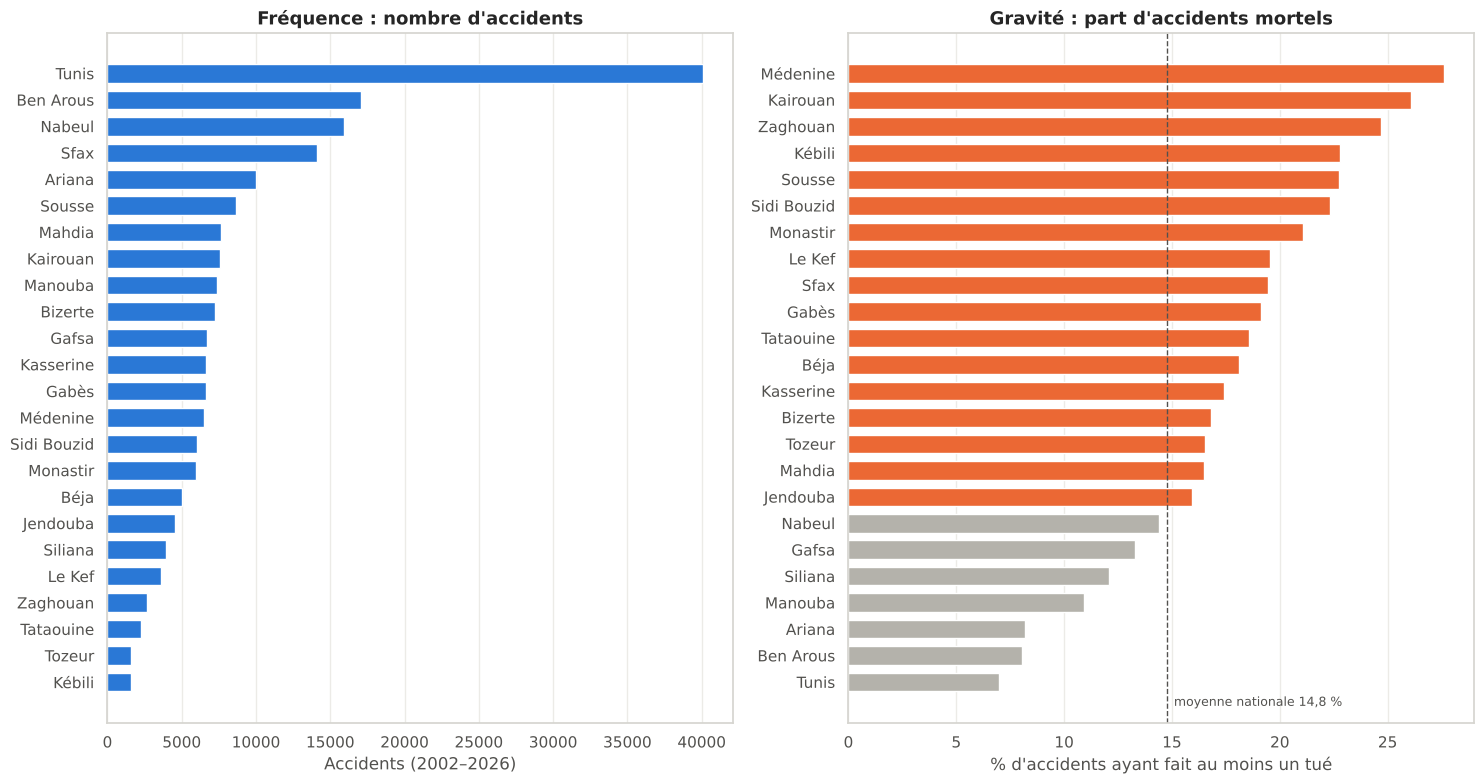

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=False)
order = gov.sort_values("accidents").index
axes[0].barh(order, gov.loc[order, "accidents"], color=BLUE, height=0.7)
axes[0].set(title="Fréquence : nombre d'accidents", xlabel="Accidents (2002–2026)")
order_g = gov.sort_values("% d'accidents mortels").index
mean_rate = acc["mortel"].mean() * 100
colors = [ORANGE if v > mean_rate else GREY for v in gov.loc[order_g, "% d'accidents mortels"]]
axes[1].barh(order_g, gov.loc[order_g, "% d'accidents mortels"], color=colors, height=0.7)
axes[1].axvline(mean_rate, color=INK_2, ls="--", lw=1)
axes[1].text(mean_rate + 0.3, -0.9, f"moyenne nationale {pct(mean_rate)}", fontsize=9, color=INK_2)
axes[1].set(title="Gravité : part d'accidents mortels", xlabel="% d'accidents ayant fait au moins un tué")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "01_gouvernorats_frequence_gravite.png")
plt.show()

Les deux classements sont presque **inversés** :
- la **fréquence** est maximale dans le Grand Tunis et sur le littoral (Tunis, Ben Arous, Nabeul, Sfax), là où se concentrent la population et le trafic ;
- la **gravité** est maximale dans les gouvernorats de l'intérieur et du Sud : à Médenine et Kairouan, plus d'un accident sur quatre est mortel (environ un sur quatre à Zaghouan), contre moins d'un sur dix à Tunis. La corrélation entre fréquence et gravité est d'ailleurs **négative** sur les 24 gouvernorats (voir ci-dessous).

Explication plausible : en ville, les accidents sont nombreux mais se produisent à faible vitesse ; sur les routes interurbaines, ils sont plus rares mais beaucoup plus violents. La section 12 vérifie que cet effet persiste quand on tient compte des autres facteurs.

Corrélation de Spearman entre fréquence et gravité (24 gouvernorats) : ρ = -0.42 (p = 0.040)


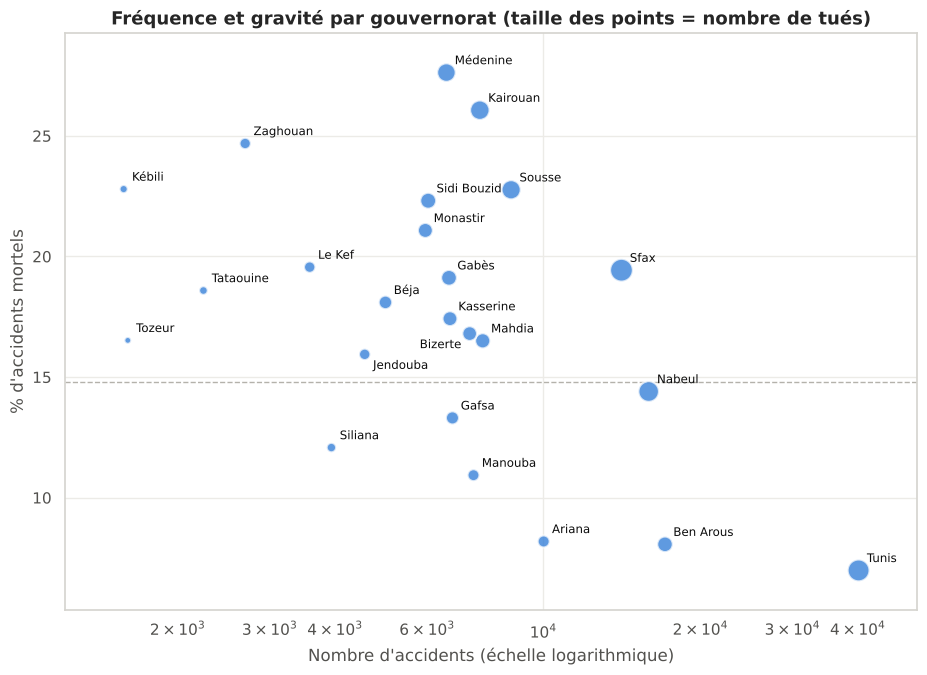

In [13]:
LABEL_SPOTS = [(6, 4, "left", "bottom"), (6, -4, "left", "top"), (-6, 4, "right", "bottom"),
               (-6, -4, "right", "top"), (0, 9, "center", "bottom"), (0, -9, "center", "top"),
               (12, 12, "left", "bottom"), (12, -12, "left", "top"),
               (-12, 12, "right", "bottom"), (-12, -12, "right", "top")]


def place_labels(ax, xs, ys, texts, obstacles=(), fontsize=8.5, leader=False):
    """Étiquette chaque point en choisissant la position qui chevauche le moins
    les autres étiquettes, les points et les textes déjà présents (obstacles).
    leader=True : étiquettes plus éloignées, reliées au point par un trait."""
    scale = 3 if leader else 1
    arrow = dict(arrowstyle="-", color=INK_2, lw=0.8, shrinkA=0, shrinkB=4) if leader else None
    renderer = ax.figure.canvas.get_renderer()
    taken = [o.get_window_extent(renderer) for o in obstacles]
    points = [Bbox.from_bounds(px - 5, py - 5, 10, 10)
              for px, py in ax.transData.transform(np.column_stack([xs, ys]))]
    for i, (x, y, text) in enumerate(zip(xs, ys, texts)):
        best = None
        for dx, dy, ha, va in LABEL_SPOTS:
            ann = ax.annotate(text, (x, y), xytext=(dx * scale, dy * scale),
                              textcoords="offset points", ha=ha, va=va,
                              fontsize=fontsize, color=INK, arrowprops=arrow)
            box = ann.get_window_extent(renderer)
            score = (sum(box.overlaps(b) for b in taken)
                     + sum(box.overlaps(b) for j, b in enumerate(points) if j != i)
                     + 5 * (not ax.bbox.contains(box.x0, box.y0) or not ax.bbox.contains(box.x1, box.y1)))
            if best is None or score < best[0]:
                if best:
                    best[1].remove()
                best = (score, ann, box)
            else:
                ann.remove()
            if score == 0:
                break
        taken.append(best[2])

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.scatter(gov["accidents"], gov["% d'accidents mortels"], s=gov["tues"] / 12, color=BLUE, alpha=0.75,
           edgecolor="white", linewidth=1.5, zorder=3)
ax.axhline(mean_rate, color=GREY, ls="--", lw=1, zorder=1)
ax.set_xscale("log")
ax.margins(x=0.08, y=0.08)
fig.canvas.draw()
place_labels(ax, gov["accidents"], gov["% d'accidents mortels"], gov.index)
ax.set(title="Fréquence et gravité par gouvernorat (taille des points = nombre de tués)",
       xlabel="Nombre d'accidents (échelle logarithmique)", ylabel="% d'accidents mortels")
fig.savefig(FIGURES / "02_frequence_vs_gravite.png")
plt.show()
rho, p = spearmanr(gov["accidents"], gov["% d'accidents mortels"])
print(f"Corrélation de Spearman entre fréquence et gravité (24 gouvernorats) : ρ = {rho:.2f} (p = {p:.3f})")

## 8. Délégations (17 % des accidents)

Rappel de la section 3 : la délégation n'est renseignée que pour 17 % des accidents. Une délégation est identifiée par le couple gouvernorat + délégation (homonymes, section 5).

In [14]:
known = acc.dropna(subset=["delegation_ar"])
print(f"Accidents avec délégation renseignée : {fmt_int(len(known))} ({len(known) / len(acc):.1%})")
coverage = (acc.assign(renseignee=acc["delegation_ar"].notna()).groupby("annee")["renseignee"].mean() * 100).round(1)
print("Part renseignée selon l'année :", coverage[coverage > 0].to_dict())

deleg_stats = (known.groupby(["gouvernorat", "delegation_ar"])
               .agg(accidents=("identifiant", "size"), tues=("tues", "sum"), blesses=("blesses", "sum"),
                    part_mortels=("mortel", "mean")).reset_index())
deleg_stats["% d'accidents mortels"] = (deleg_stats.pop("part_mortels") * 100).round(1)
deleg_stats.sort_values("accidents", ascending=False).head(15).reset_index(drop=True)

Accidents avec délégation renseignée : 34 235 (17.2%)
Part renseignée selon l'année : {2015: 0.1, 2017: 17.9, 2018: 0.1, 2019: 19.9, 2020: 21.7, 2021: 99.4, 2022: 99.4, 2023: 100.0, 2024: 97.3, 2025: 99.9, 2026: 98.7}


,gouvernorat,delegation_ar,accidents,tues,blesses,% d'accidents mortels
0,Tunis,تونس,831,114,1039,13.2
1,Mahdia,المهدية,822,47,1044,5.5
2,Tunis,سيدي حسين,601,78,708,12.5
3,Monastir,المنستير,540,80,739,13.9
4,Tunis,المرسى,489,78,670,13.5
5,Gafsa,قفصة الجنوبية,474,41,670,7.4
6,Tunis,باردو,421,44,549,10.0
7,Nabeul,قرمبالية,421,81,621,16.9
8,Tunis,باب البحر,421,29,527,6.9
9,Ben Arous,المروج,401,27,480,6.7


In [15]:
share = deleg_stats.assign(part=lambda d: d.accidents / d.groupby("gouvernorat").accidents.transform("sum") * 100)
concentration = (share.sort_values("part", ascending=False).groupby("gouvernorat").head(1)
                 .rename(columns={"delegation_ar": "délégation la plus touchée", "part": "% des accidents du gouvernorat"})
                 [["gouvernorat", "délégation la plus touchée", "accidents", "% des accidents du gouvernorat"]]
                 .sort_values("% des accidents du gouvernorat", ascending=False).round(1).reset_index(drop=True))
concentration.head(10)

,gouvernorat,délégation la plus touchée,accidents,% des accidents du gouvernorat
0,Tozeur,توزر,166,59.3
1,Monastir,المنستير,540,47.7
2,Zaghouan,زغوان,234,45.0
3,Mahdia,المهدية,822,35.6
4,Manouba,منوبة,286,32.9
5,Béja,مجاز الباب,311,32.9
6,Gafsa,قفصة الجنوبية,474,30.3
7,Tataouine,تطاوين الشمالية,106,29.7
8,Le Kef,تاجروين,183,26.9
9,Kasserine,القصرين الشمالية,363,25.6


**Lecture** :
- **La délégation n'est renseignée de façon systématique que depuis 2021** (près de 100 % des accidents), contre presque jamais avant 2017. L'analyse par délégation décrit donc en pratique les **années 2021 à 2026**, et ne peut pas être comparée aux résultats par gouvernorat, qui couvrent 25 ans.
- Dans plusieurs gouvernorats (Tozeur, Monastir, Zaghouan), la délégation chef-lieu concentre à elle seule entre 45 % et 60 % des accidents : l'accidentalité suit la concentration urbaine.

---
# Partie 4 — Temporalité

## 9. Évolution annuelle

2002 → 2025 : accidents -55 %, tués -21 %, part d'accidents mortels 11.5 % → 20.5 %
2026 (année incomplète, non représentée) : 3 224 accidents, part d'accidents mortels 26.2 %


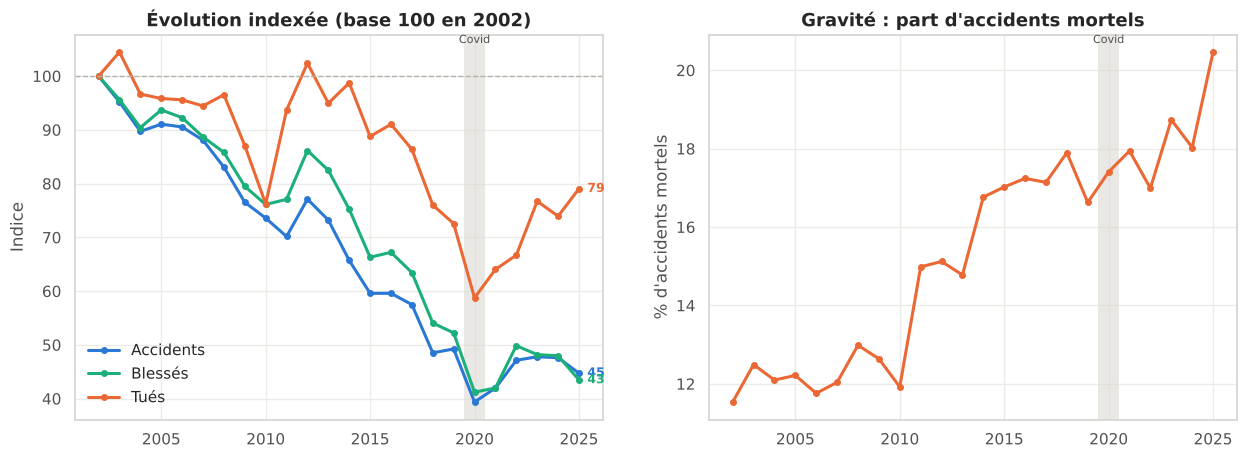

,accidents,blesses,tues,% d'accidents mortels,tués pour 100 accidents
annee,,,,,
2002,12127,16416,1585,11.5,13.1
2003,11544,15698,1656,12.5,14.3
2004,10879,14845,1532,12.1,14.1
2005,11043,15382,1519,12.2,13.8
2006,10980,15147,1515,11.8,13.8
2007,10681,14559,1497,12.0,14.0
2008,10073,14085,1530,13.0,15.2
2009,9281,13050,1380,12.6,14.9
2010,8924,12495,1208,11.9,13.5


In [16]:
yearly = acc.groupby("annee").agg(accidents=("identifiant", "size"), blesses=("blesses", "sum"),
                                  tues=("tues", "sum"), part_mortels=("mortel", "mean"))
yearly["part_mortels"] *= 100
yearly["tués pour 100 accidents"] = yearly["tues"] / yearly["accidents"] * 100
yearly = yearly.rename(columns={"part_mortels": "% d'accidents mortels"})
complete_years = yearly.loc[sorted(acc.loc[acc["annee_complete"], "annee"].unique())]
index = complete_years[["accidents", "blesses", "tues"]] / complete_years[["accidents", "blesses", "tues"]].iloc[0] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for col, color, label in [("accidents", BLUE, "Accidents"), ("blesses", AQUA, "Blessés"), ("tues", ORANGE, "Tués")]:
    axes[0].plot(index.index, index[col], color=color, lw=2.2, marker="o", ms=4, label=label)
    axes[0].annotate(f"{index[col].iloc[-1]:.0f}", (index.index[-1], index[col].iloc[-1]), xytext=(6, 0),
                     textcoords="offset points", va="center", fontsize=9, color=color, fontweight="bold")
axes[0].axhline(100, color=GREY, lw=1, ls="--")
axes[0].set(title=f"Évolution indexée (base 100 en {index.index[0]})", ylabel="Indice")
axes[0].legend(frameon=False, loc="lower left")
axes[1].plot(complete_years.index, complete_years["% d'accidents mortels"], color=ORANGE, lw=2.2, marker="o", ms=4)
axes[1].set(title="Gravité : part d'accidents mortels", ylabel="% d'accidents mortels")
for ax in axes:
    ax.axvspan(2019.5, 2020.5, color=LIGHT_GREY, alpha=0.6, lw=0)
    ax.text(2020, ax.get_ylim()[1], "Covid", ha="center", va="top", fontsize=8, color=INK_2)
    ax.set_xlabel("")
fig.savefig(FIGURES / "03_evolution_annuelle.png")
plt.show()

MORT = "% d'accidents mortels"
partial = yearly.iloc[-1]
print(f"{index.index[0]} → {index.index[-1]} : accidents {index['accidents'].iloc[-1] - 100:+.0f} %, "
      f"tués {index['tues'].iloc[-1] - 100:+.0f} %, part d'accidents mortels "
      f"{complete_years[MORT].iloc[0]:.1f} % → {complete_years[MORT].iloc[-1]:.1f} %")
print(f"{yearly.index[-1]} (année incomplète, non représentée) : {fmt_int(partial['accidents'])} accidents, "
      f"part d'accidents mortels {partial[MORT]:.1f} %")
complete_years.round(1)

C'est le résultat le plus frappant de l'étude :
- **le nombre d'accidents a été divisé par plus de deux** entre 2002 et 2025 ;
- **le nombre de tués a beaucoup moins baissé**, si bien que la **part d'accidents mortels a fortement augmenté**.

Deux explications possibles, qu'il ne faut pas confondre :
1. une **vraie aggravation** des accidents (vitesse, composition du parc, deux-roues…) ;
2. un **biais d'enregistrement** : si les accidents légers sont de moins en moins enregistrés par les forces de l'ordre alors que les accidents mortels le sont toujours, la gravité moyenne augmente mécaniquement.

Les données ne permettent pas de trancher. Un actuaire devrait recouper avec les déclarations de sinistres des assureurs. La part d'accidents mortels encore plus élevée en 2026, année incomplète, va dans le sens d'un enregistrement plus rapide des accidents graves que des accidents légers.

## 10. Mois, jours de la semaine et heures

Les mois n'ont pas le même nombre de jours : comparer des totaux mensuels avantage mécaniquement les mois de 31 jours. On compare donc le **nombre moyen d'accidents par jour** de chaque mois.

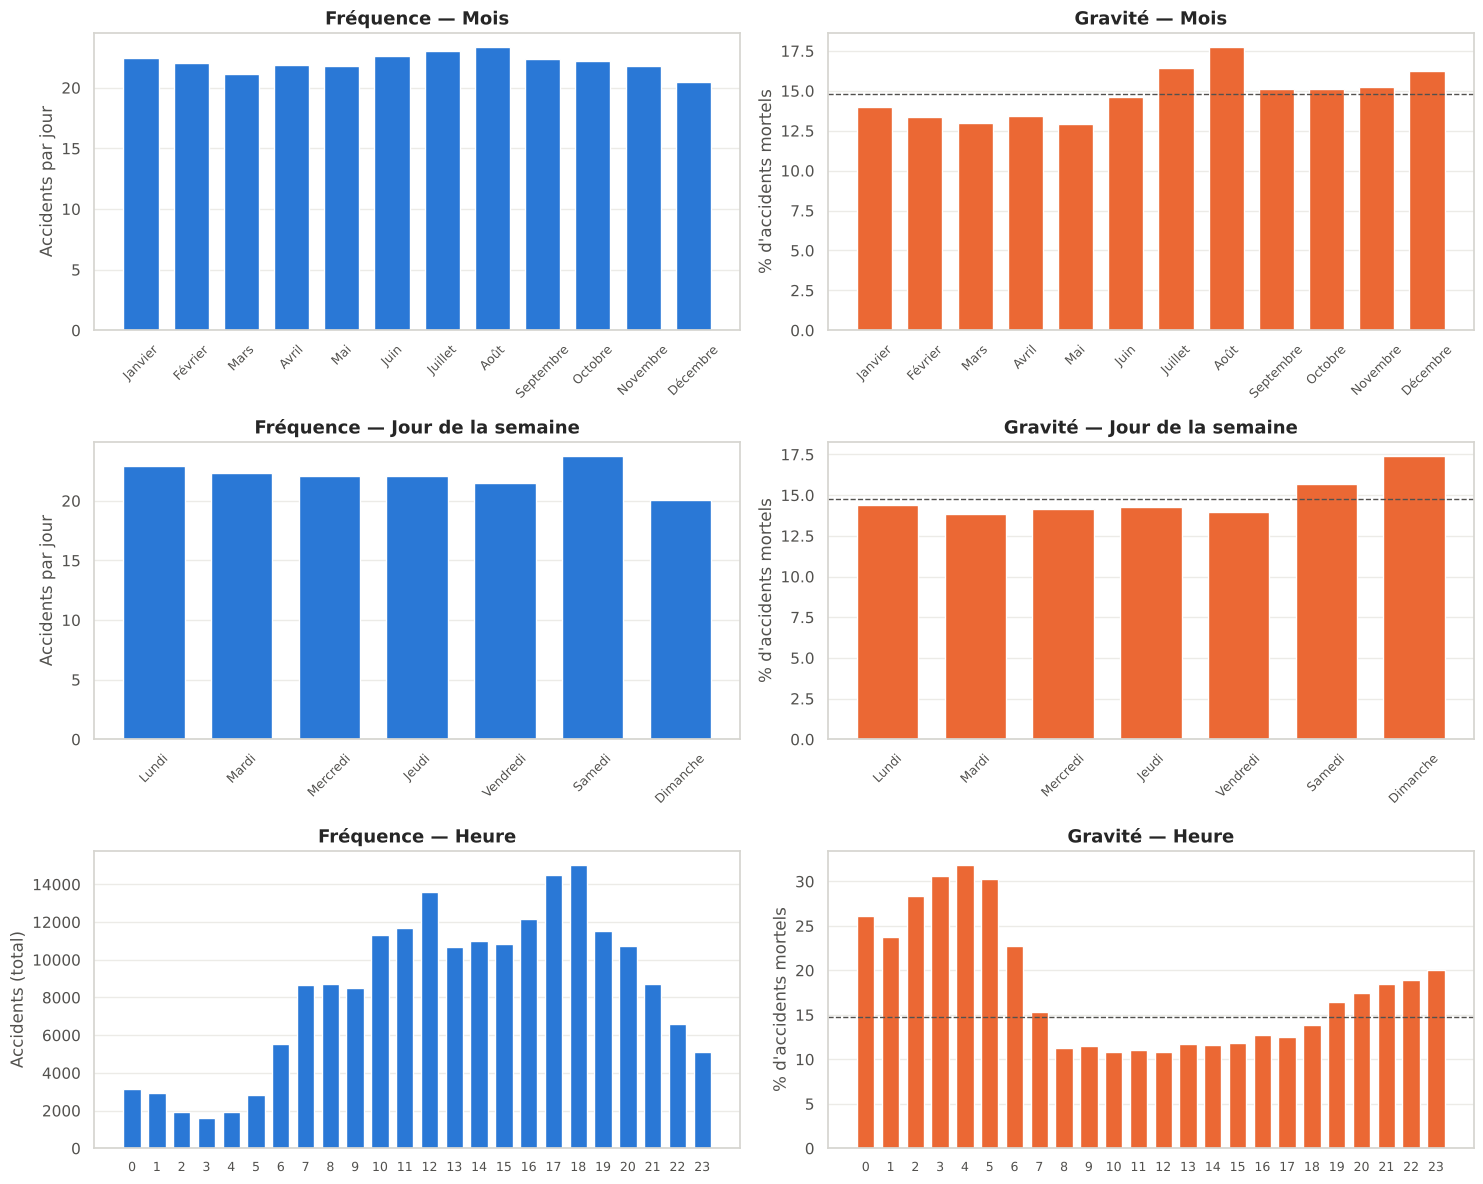

In [17]:
calendar = pd.date_range(acc["date"].min(), acc["date"].max(), freq="D")
days_in_data = pd.Series(calendar.month).map(dict(enumerate(MOIS_ORDRE, start=1))).value_counts()

monthly = acc.groupby("mois", observed=False).agg(accidents=("identifiant", "size"), tues=("tues", "sum"),
                                                  part_mortels=("mortel", "mean"))
monthly["accidents par jour"] = monthly["accidents"] / days_in_data.reindex(MOIS_ORDRE).values
monthly["% d'accidents mortels"] = monthly.pop("part_mortels") * 100

weekly = acc.groupby("jour_semaine", observed=False).agg(accidents=("identifiant", "size"), part_mortels=("mortel", "mean"))
weekly["accidents par jour"] = weekly["accidents"] / pd.Series(calendar.dayofweek).map(dict(enumerate(JOURS_ORDRE))).value_counts().reindex(JOURS_ORDRE).values
weekly["% d'accidents mortels"] = weekly.pop("part_mortels") * 100

hourly = acc.groupby("heure").agg(accidents=("identifiant", "size"), part_mortels=("mortel", "mean"))
hourly["% d'accidents mortels"] = hourly.pop("part_mortels") * 100

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
panels = [(monthly, "Mois"), (weekly, "Jour de la semaine"), (hourly, "Heure")]
for row, (table, label) in enumerate(panels):
    x = [str(i) for i in table.index]
    freq = table["accidents par jour"] if "accidents par jour" in table else table["accidents"]
    axes[row, 0].bar(x, freq, color=BLUE, width=0.7)
    axes[row, 0].set_title(f"Fréquence — {label}")
    axes[row, 0].set_ylabel("Accidents par jour" if "accidents par jour" in table else "Accidents (total)")
    axes[row, 1].bar(x, table["% d'accidents mortels"], color=ORANGE, width=0.7)
    axes[row, 1].axhline(acc["mortel"].mean() * 100, color=INK_2, ls="--", lw=1)
    axes[row, 1].set_title(f"Gravité — {label}")
    axes[row, 1].set_ylabel("% d'accidents mortels")
    for ax in axes[row]:
        ax.tick_params(axis="x", rotation=45 if row < 2 else 0, labelsize=9)
        ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "04_mois_jours_heures.png")
plt.show()

In [18]:
summary_time = pd.DataFrame({
    "le plus d'accidents": [monthly["accidents par jour"].idxmax(), weekly["accidents par jour"].idxmax(),
                            f"{hourly['accidents'].idxmax()} h"],
    "le moins d'accidents": [monthly["accidents par jour"].idxmin(), weekly["accidents par jour"].idxmin(),
                             f"{hourly['accidents'].idxmin()} h"],
    "le plus grave (% mortels)": [monthly[MORT].idxmax(), weekly[MORT].idxmax(), f"{hourly[MORT].idxmax()} h"],
}, index=["Mois", "Jour", "Heure"])
summary_time

,le plus d'accidents,le moins d'accidents,le plus grave (% mortels)
Mois,Août,Décembre,Août
Jour,Samedi,Dimanche,Dimanche
Heure,18 h,3 h,4 h


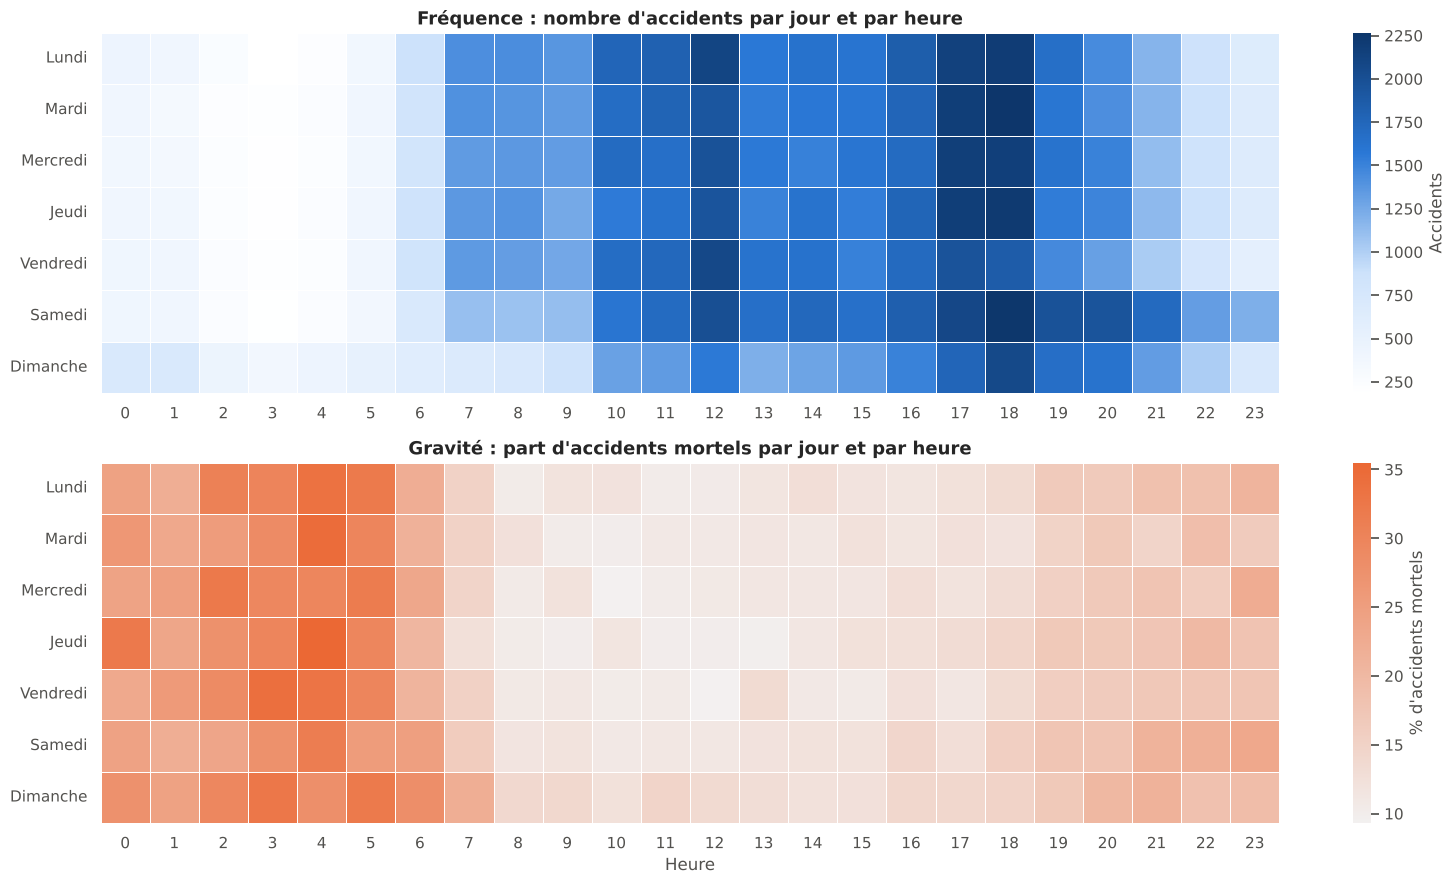

In [19]:
pivot = acc.pivot_table(index="jour_semaine", columns="heure", values="identifiant", aggfunc="size", observed=False)
pivot_mortel = acc.pivot_table(index="jour_semaine", columns="heure", values="mortel", aggfunc="mean", observed=False) * 100

fig, axes = plt.subplots(2, 1, figsize=(16, 9))
sns.heatmap(pivot, cmap=SEQ, ax=axes[0], cbar_kws={"label": "Accidents"}, linewidths=0.5, linecolor="white")
axes[0].set(title="Fréquence : nombre d'accidents par jour et par heure", xlabel="", ylabel="")
sns.heatmap(pivot_mortel, cmap=sns.light_palette(ORANGE, as_cmap=True), ax=axes[1],
            cbar_kws={"label": "% d'accidents mortels"}, linewidths=0.5, linecolor="white")
axes[1].set(title="Gravité : part d'accidents mortels par jour et par heure", xlabel="Heure", ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "05_jour_heure.png")
plt.show()

**Lecture** :
- **Fréquence** : les accidents se concentrent en fin d'après-midi et en début de soirée (pic à 18 h, heures de pointe) et le samedi. L'effet saisonnier est **modéré** une fois ramené au nombre de jours : environ 23 accidents par jour en juillet–août contre 20 à 21 en décembre et en mars.
- **Gravité** : elle suit le profil **inverse** de la fréquence. Entre 0 h et 6 h, il y a peu d'accidents, mais entre un quart et un tiers d'entre eux sont mortels (jusqu'à 32 % à 4 h), contre environ 11 % en journée : vitesse plus élevée sur des routes dégagées, fatigue, alcool, visibilité réduite, secours plus lents. L'été (août) et le dimanche sont aussi plus graves.
- La carte de chaleur de la gravité montre que la nuit est dangereuse **tous les jours de la semaine** : l'heure compte bien plus que le jour.

---
# Partie 5 — Causes et types de collision

## 11. Causes déclarées

In [20]:
causes = acc.groupby(["cause", "cause_ar"]).agg(accidents=("identifiant", "size"), tues=("tues", "sum"),
                                               part_mortels=("mortel", "mean")).reset_index()
causes["% des accidents"] = causes["accidents"] / len(acc) * 100
causes["% d'accidents mortels"] = causes.pop("part_mortels") * 100
causes = causes.sort_values("accidents", ascending=False).reset_index(drop=True)
print(f"Les 3 premières causes représentent {causes['% des accidents'].head(3).sum():.0f} % des accidents.")
causes.round(1)

Les 3 premières causes représentent 57 % des accidents.


,cause,cause_ar,accidents,tues,% des accidents,% d'accidents mortels
0,Inattention,السهو وعدم الانتباه,41906,4120,21.0,9.4
1,Traversée de la chaussée (piéton),شق الطريق,39102,4060,19.6,10.3
2,Vitesse excessive,السرعة,32836,10068,16.5,26.7
3,Refus de priorité,عدم احترام الاولوية,15267,1239,7.7,7.5
4,Heurt soudain (« mdahma »),المداهمة,13823,1740,6.9,11.1
5,Ne pas tenir sa droite,عدم ملازمة اليمين,11654,3743,5.8,23.8
6,Changement de direction,تغيير اتجاه,7588,839,3.8,9.6
7,Dépassement interdit,المجاوزة الممنوعة,5265,1676,2.6,22.3
8,Marche arrière,السير الى الوراء,4044,316,2.0,7.6
9,Non-respect du stop,عدم احترام علامة قف,3588,409,1.8,9.3


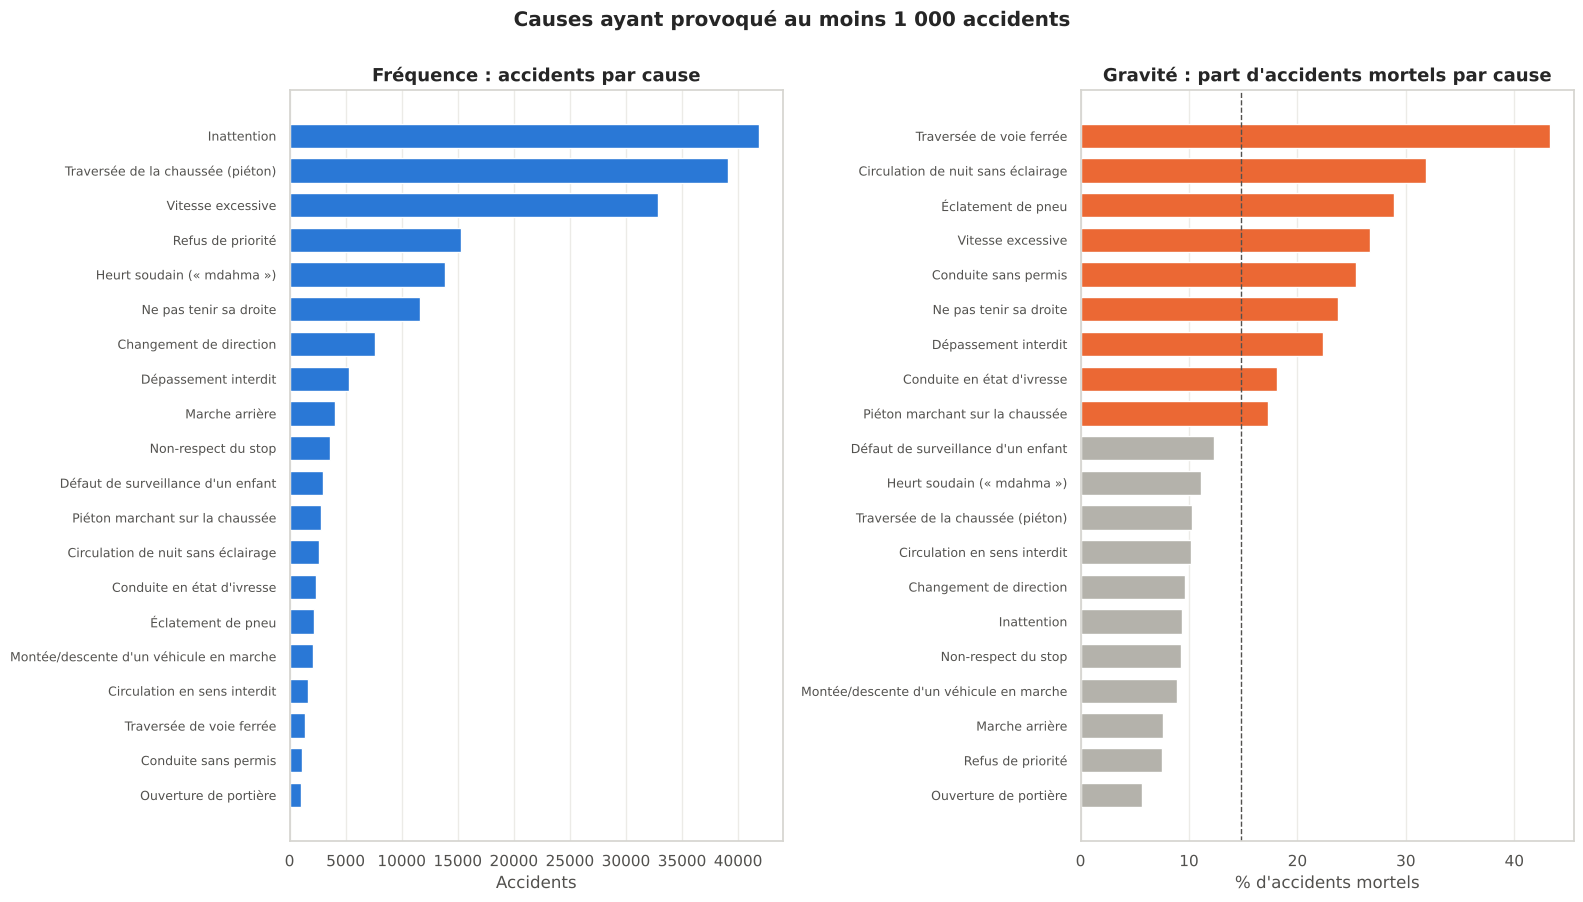

In [21]:
top = causes[causes["accidents"] >= 1000].copy()
fig, axes = plt.subplots(1, 2, figsize=(16, 9))
order = top.sort_values("accidents")
axes[0].barh(order["cause"], order["accidents"], color=BLUE, height=0.7)
axes[0].set(title="Fréquence : accidents par cause", xlabel="Accidents")
order_g = top.sort_values("% d'accidents mortels")
colors = [ORANGE if v > mean_rate else GREY for v in order_g["% d'accidents mortels"]]
axes[1].barh(order_g["cause"], order_g["% d'accidents mortels"], color=colors, height=0.7)
axes[1].axvline(mean_rate, color=INK_2, ls="--", lw=1)
axes[1].set(title="Gravité : part d'accidents mortels par cause", xlabel="% d'accidents mortels")
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle("Causes ayant provoqué au moins 1 000 accidents", fontweight="bold", y=1.0)
fig.tight_layout()
fig.savefig(FIGURES / "06_causes.png")
plt.show()

Trois causes représentent à elles seules plus de la moitié des accidents (57 %) : l'**inattention**, la **traversée de la chaussée par un piéton** et la **vitesse excessive**.

Mais les causes les plus **fréquentes** ne sont pas les plus **meurtrières**. Parmi les causes d'au moins 1 000 accidents, les plus souvent mortelles sont :
- la traversée d'une **voie ferrée** (plus de 40 % d'accidents mortels) ;
- la **circulation de nuit sans éclairage** ;
- l'**éclatement d'un pneu** ;
- la **vitesse excessive** (plus d'un accident sur quatre mortel, et 30 % des tués à elle seule) ;
- la conduite **sans permis**.

Ce sont des causes typiques des trajets interurbains, rapides et nocturnes, ce qui rejoint les constats des sections 7 et 10. À l'inverse, l'inattention, première cause en nombre, est relativement peu grave (9 % d'accidents mortels) : ce sont surtout des accidents urbains à faible vitesse.

## 12. Usagers impliqués (type de collision)

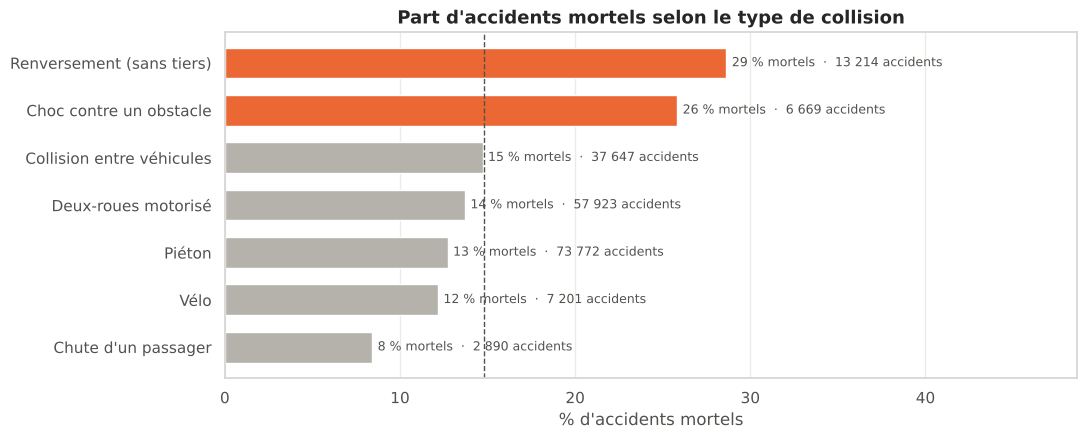

,accidents,tues,% des accidents,% d'accidents mortels
collision,,,,
Piéton,73772,9615,37.0,12.7
Deux-roues motorisé,57923,8494,29.1,13.7
Collision entre véhicules,37647,8024,18.9,14.7
Renversement (sans tiers),13214,4389,6.6,28.6
Vélo,7201,884,3.6,12.2
Choc contre un obstacle,6669,2106,3.3,25.8
Chute d'un passager,2890,243,1.4,8.4


In [22]:
coll = acc.groupby("collision").agg(accidents=("identifiant", "size"), tues=("tues", "sum"), part_mortels=("mortel", "mean"))
coll["% des accidents"] = coll["accidents"] / len(acc) * 100
coll["% d'accidents mortels"] = coll.pop("part_mortels") * 100
coll = coll.sort_values("accidents", ascending=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
order = coll.sort_values("% d'accidents mortels")
bars = ax.barh(order.index, order["% d'accidents mortels"], color=[ORANGE if v > mean_rate else GREY
                                                                   for v in order["% d'accidents mortels"]], height=0.65)
ax.bar_label(bars, labels=[f"{m:.0f} % mortels  ·  {fmt_int(n)} accidents"
                           for m, n in zip(order["% d'accidents mortels"], order["accidents"])],
             padding=4, fontsize=9, color=INK_2)
ax.axvline(mean_rate, color=INK_2, ls="--", lw=1)
ax.set(title="Part d'accidents mortels selon le type de collision", xlabel="% d'accidents mortels",
       xlim=(0, order["% d'accidents mortels"].max() * 1.7))
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "07_types_collision.png")
plt.show()
coll.round(1)

- Les **piétons** et les **deux-roues motorisés** sont impliqués dans les deux tiers des accidents : ce sont les usagers les plus exposés **en nombre**.
- Les accidents **sans tiers** (renversement, choc contre un obstacle) sont rares, mais plus d'un sur quatre est mortel : ils correspondent typiquement à une perte de contrôle à grande vitesse. La partie 7 montre que cet écart disparaît presque une fois la vitesse et le type de route pris en compte.

---
# Partie 6 — Conséquences humaines et relations statistiques

## 13. Blessés et tués par accident

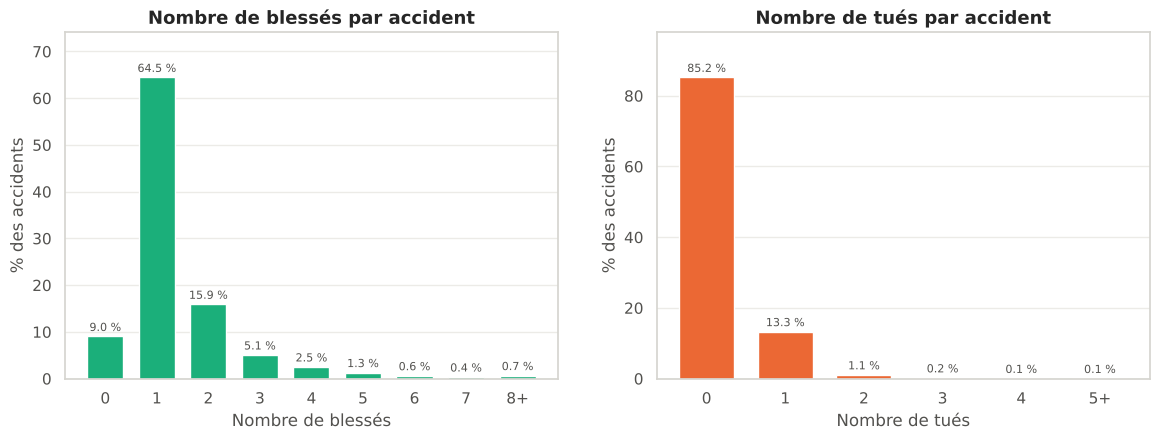

,count,mean,std,min,50%,90%,99%,max,asymétrie
blesses,199316.0,1.42,1.47,0.0,1.0,3.0,7.0,132.0,16.03
tues,199316.0,0.17,0.46,0.0,0.0,1.0,2.0,30.0,5.60


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, cap, color, label in [(axes[0], "blesses", 8, AQUA, "blessés"), (axes[1], "tues", 5, ORANGE, "tués")]:
    counts = acc[col].clip(upper=cap).value_counts().sort_index()
    shares = counts / counts.sum() * 100
    bars = ax.bar([str(i) if i < cap else f"{cap}+" for i in counts.index], shares, color=color, width=0.7)
    ax.bar_label(bars, fmt="%.1f %%", padding=2, fontsize=8, color=INK_2)
    ax.set(title=f"Nombre de {label} par accident", xlabel=f"Nombre de {label}", ylabel="% des accidents",
           ylim=(0, shares.max() * 1.15))
    ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "08_victimes_par_accident.png")
plt.show()

stats = acc[["blesses", "tues"]].describe(percentiles=[0.5, 0.9, 0.99]).T
stats["asymétrie"] = acc[["blesses", "tues"]].skew()
stats.round(2)

La plupart des accidents font **un blessé et aucun tué**. Les distributions sont très **asymétriques** (asymétrie de 16 pour les blessés) : quelques accidents collectifs tirent la moyenne vers le haut. C'est la raison pour laquelle on utilise ci-après des méthodes **non paramétriques** (Spearman, Mann-Whitney, Kruskal-Wallis), qui ne supposent pas de loi normale.

## 14. Corrélations

Tués vs blessés : ρ = -0.36 (p < 0,001)


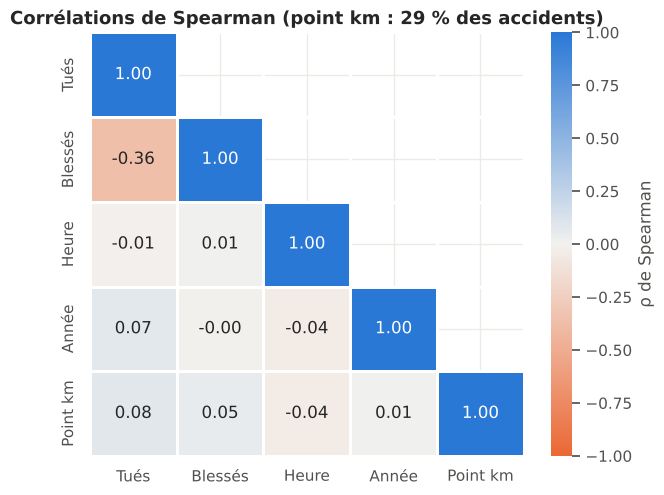

In [24]:
num = acc[["tues", "blesses", "heure", "annee", "point_km"]].rename(
    columns={"tues": "Tués", "blesses": "Blessés", "heure": "Heure", "annee": "Année", "point_km": "Point km"})
corr = num.corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV, vmin=-1, vmax=1, center=0, linewidths=2, linecolor="white",
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cbar_kws={"label": "ρ de Spearman"}, ax=ax)
ax.set_title("Corrélations de Spearman (point km : 29 % des accidents)")
fig.savefig(FIGURES / "09_correlations.png")
plt.show()

rho, p = spearmanr(acc["tues"], acc["blesses"])
print(f"Tués vs blessés : ρ = {rho:.2f} (p < 0,001)")

- **Tués et blessés** sont **négativement** corrélés (ρ ≈ −0,36). Ce n'est pas un lien de cause à effet : il reflète deux profils d'accidents différents. Un piéton renversé donne souvent un tué *ou* un blessé, alors que les accidents de véhicules occupés font plusieurs blessés.
- L'heure et l'année ont des corrélations quasi nulles avec le nombre de victimes **au niveau de chaque accident**, alors que la part d'accidents mortels varie nettement par heure et par année (sections 9 et 10). Il n'y a pas de contradiction : un coefficient calculé sur des données individuelles composées surtout de 0 et de 1 reste faible même quand une tendance agrégée existe. Les relations ne sont d'ailleurs pas monotones (pic de gravité la nuit, creux le jour).

## 15. Tests d'association avec la gravité (χ² et V de Cramér)

Pour chaque variable qualitative, on teste :

$$H_0 : \text{la part d'accidents mortels est la même dans toutes les modalités} \qquad H_1 : \text{elle diffère}$$

**Attention à la taille de l'échantillon.** Avec 200 000 accidents, la moindre différence est « significative » (p-value ≈ 0). La p-value ne dit donc pas si l'écart est important. On mesure l'**intensité** de l'association par le **V de Cramér**, avec les seuils de Cohen pour un tableau à 2 colonnes : 0,1 = faible, 0,3 = moyenne, 0,5 = forte.

In [25]:
def cramer_test(var: str) -> dict:
    table = pd.crosstab(acc[var], acc["mortel"])
    chi2, p, dof, expected = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    strength = "négligeable" if v < 0.1 else "faible" if v < 0.3 else "moyenne" if v < 0.5 else "forte"
    return {"variable": var, "modalités": table.shape[0], "χ²": round(chi2, 1), "ddl": dof, "p-value": p,
            "effectifs théoriques < 5": int((expected < 5).sum()), "V de Cramér": round(v, 3), "intensité": strength}


tests = pd.DataFrame([cramer_test(v) for v in ["collision", "autorite", "gouvernorat", "tranche_horaire",
                                                "cause", "jour_semaine", "mois", "week_end"]])
tests.sort_values("V de Cramér", ascending=False).reset_index(drop=True)

,variable,modalités,χ²,ddl,p-value,effectifs théoriques < 5,V de Cramér,intensité
0,cause,31,9915.3,30,0.000000e+00,3,0.223,faible
1,autorite,2,9043.8,1,0.000000e+00,0,0.213,faible
2,gouvernorat,24,6380.3,23,0.000000e+00,0,0.179,faible
3,collision,7,3091.0,6,0.000000e+00,0,0.125,faible
4,tranche_horaire,4,2820.3,3,0.000000e+00,0,0.119,faible
5,mois,12,342.7,11,8.490097e-67,0,0.041,négligeable
6,jour_semaine,7,213.4,6,2.651434e-43,0,0.033,négligeable
7,week_end,2,174.5,1,7.850951e-40,0,0.030,négligeable


Tous les tests rejettent l'indépendance, comme attendu avec un tel effectif. Le V de Cramér remet les choses en perspective :
- la **cause**, l'**autorité** (police / garde nationale), le **gouvernorat**, le **type de collision** et la **tranche horaire** ont une association **faible** mais réelle avec la gravité (3 cellules du tableau des causes ont un effectif théorique < 5 : des causes très rares, sans effet sur la conclusion) ;
- le **mois**, le **jour** et le **week-end** ont une association **négligeable**, même si leurs écarts de gravité sont visibles sur les graphiques.

Aucune variable n'a d'association « moyenne » ou « forte » à elle seule : la gravité d'un accident résulte de la **combinaison** de plusieurs facteurs, d'où le modèle multivarié de la partie 7.

## 16. Comparaisons de groupes (tests non paramétriques et tailles d'effet)

In [26]:
police = acc.loc[acc["autorite_ar"] == "شرطة", "blesses"]
garde = acc.loc[acc["autorite_ar"] == "حرس", "blesses"]
u, p_u = mannwhitneyu(police, garde)
rank_biserial = 1 - 2 * u / (len(police) * len(garde))      # taille d'effet de Mann-Whitney

groups = [g["blesses"].values for _, g in acc.groupby("tranche_horaire", observed=True)]
h, p_h = kruskal(*groups)
epsilon2 = (h - len(groups) + 1) / (len(acc) - len(groups))  # taille d'effet de Kruskal-Wallis

pd.DataFrame([
    {"comparaison": "Blessés par accident : police vs garde nationale", "test": "Mann-Whitney",
     "statistique": round(u), "p-value": p_u,
     "moyennes": f"police {police.mean():.2f} · garde {garde.mean():.2f}",
     "taille d'effet": f"corrélation rang-bisériale = {rank_biserial:.2f}"},
    {"comparaison": "Blessés par accident selon la tranche horaire", "test": "Kruskal-Wallis",
     "statistique": round(h, 1), "p-value": p_h,
     "moyennes": " · ".join(f"{k.split(' ')[0]} {g.mean():.2f}" for k, g in
                            zip(acc["tranche_horaire"].cat.categories, groups)),
     "taille d'effet": f"ε² = {epsilon2:.3f}"},
])

,comparaison,test,statistique,p-value,moyennes,taille d'effet
0,Blessés par accident : police vs garde nationale,Mann-Whitney,4.042334e+09,0.000000e+00,police 1.27 · garde 1.68,corrélation rang-bisériale = 0.12
1,Blessés par accident selon la tranche horaire,Kruskal-Wallis,6.986000e+02,4.156189e-151,Nuit 1.64 · Matin 1.40 · Après-midi 1.39 · Soirée 1.42,ε² = 0.003


- **Police / garde nationale** : les accidents constatés par la garde nationale (routes interurbaines, zones rurales) font significativement plus de blessés. La taille d'effet est **faible** : la différence est réelle mais modeste à l'échelle d'un accident.
- **Tranches horaires** : les accidents de nuit font un peu plus de blessés, mais ε² ≈ 0 indique que la tranche horaire n'explique qu'une part **infime** de la variabilité du nombre de blessés. L'effet de la nuit porte surtout sur la **mortalité** (section 10), pas sur le nombre de blessés.

---
# Partie 7 — Modèle multivarié : qu'est-ce qui rend un accident mortel ?

Les analyses précédentes regardent les facteurs **un par un**. Or ils sont liés entre eux : les accidents de la garde nationale ont lieu sur des routes rapides, plus souvent la nuit, dans des gouvernorats de l'intérieur… La part d'accidents mortels plus élevée à Kairouan vient-elle du gouvernorat lui-même, ou de ce qu'on y roule davantage sur route ?

Une **régression logistique** estime l'effet de chaque facteur **toutes choses égales par ailleurs** sur la probabilité qu'un accident soit mortel. Ses coefficients se lisent en **rapports de cotes** (*odds ratios*, OR) :
- OR = 1 : pas d'effet par rapport à la modalité de référence ;
- OR = 2 : la cote d'un accident mortel est multipliée par 2.

Modalités de référence : Tunis, police, après-midi, jour de semaine, collision entre véhicules, cause « inattention ». L'année est incluse en variable continue pour capter la tendance.

In [27]:
top_causes = causes.loc[causes["accidents"] >= 2000, "cause"].tolist()
model_df = acc.assign(
    cause_m=np.where(acc["cause"].isin(top_causes), acc["cause"], "Autres causes"),
    annee_c=(acc["annee"] - 2014) / 10,          # effet pour 10 ans, centré sur 2014
)
REFERENCES = {"gouvernorat": "Tunis", "autorite": AUTORITE["شرطة"], "tranche_horaire": "Après-midi (12h–18h)",
              "collision": "Collision entre véhicules", "cause_m": "Inattention"}

dummies = []
for var, ref in REFERENCES.items():
    d = pd.get_dummies(model_df[var].astype(str), prefix=var, prefix_sep=" = ", dtype=float)
    dummies.append(d.drop(columns=f"{var} = {ref}"))
X = pd.concat(dummies + [model_df[["week_end"]].astype(float).rename(columns={"week_end": "week-end"}),
                         model_df[["annee_c"]].rename(columns={"annee_c": "année (par 10 ans)"})], axis=1)
y = model_df["mortel"].values

logit = LogisticRegression(C=1e10, max_iter=5000).fit(X, y)
design = np.column_stack([np.ones(len(X)), X.values])
p_hat = logit.predict_proba(X)[:, 1]
cov = np.linalg.pinv(design.T @ (design * (p_hat * (1 - p_hat))[:, None]))
beta = np.r_[logit.intercept_, logit.coef_.ravel()]
se = np.sqrt(np.diag(cov))
results = pd.DataFrame({"coefficient": beta, "écart-type": se, "p-value": 2 * norm.sf(np.abs(beta / se)),
                        "OR": np.exp(beta), "OR IC 95 % bas": np.exp(beta - 1.96 * se),
                        "OR IC 95 % haut": np.exp(beta + 1.96 * se)},
                       index=["constante"] + list(X.columns)).drop("constante")
print(f"{X.shape[1]} variables explicatives (indicatrices) | {len(X):,} accidents".replace(",", " "))
print(f"AUC du modèle : {roc_auc_score(y, p_hat):.3f}  (capacité à distinguer accidents mortels et non mortels)")
results.sort_values("OR", ascending=False).round(3)

51 variables explicatives (indicatrices) | 199 316 accidents
AUC du modèle : 0.743  (capacité à distinguer accidents mortels et non mortels)


,coefficient,écart-type,p-value,OR,OR IC 95 % bas,OR IC 95 % haut
gouvernorat = Médenine,0.963,0.037,0.000,2.620,2.439,2.815
cause_m = Vitesse excessive,0.932,0.025,0.000,2.540,2.419,2.667
autorite = Garde nationale (routes et zones rurales),0.901,0.017,0.000,2.462,2.382,2.545
cause_m = Autres causes,0.858,0.034,0.000,2.359,2.209,2.519
cause_m = Éclatement de pneu,0.825,0.056,0.000,2.281,2.044,2.546
tranche_horaire = Nuit (0h–6h),0.820,0.024,0.000,2.271,2.168,2.380
gouvernorat = Kairouan,0.814,0.036,0.000,2.257,2.103,2.422
gouvernorat = Zaghouan,0.792,0.052,0.000,2.209,1.995,2.446
gouvernorat = Monastir,0.771,0.040,0.000,2.163,2.001,2.338
gouvernorat = Sidi Bouzid,0.747,0.039,0.000,2.111,1.954,2.281


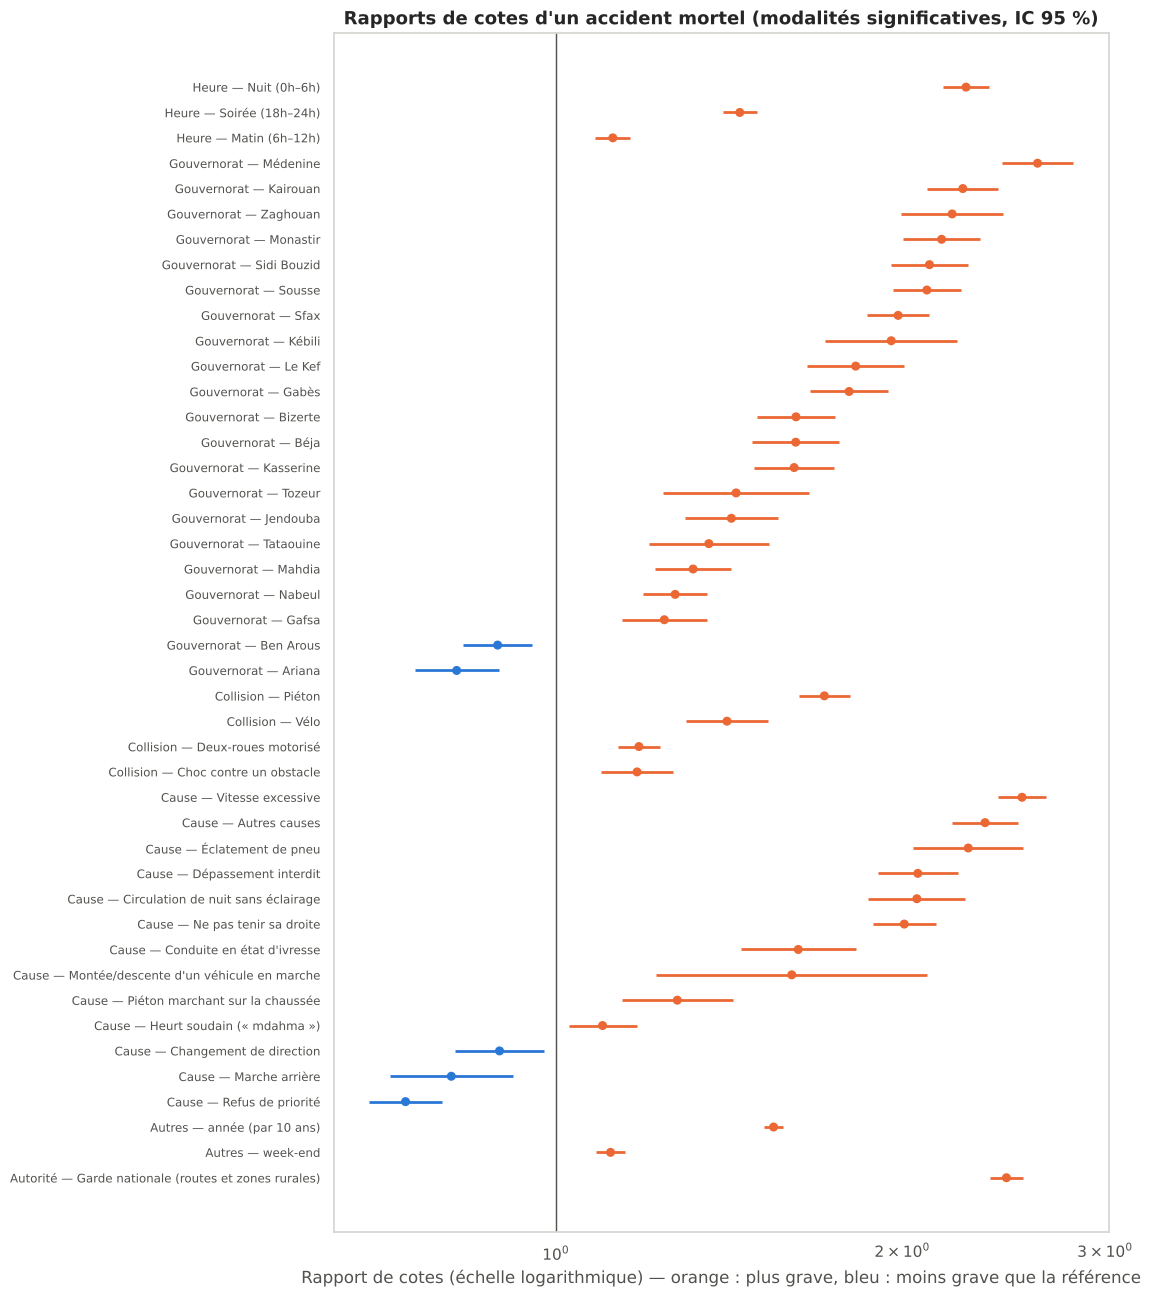

In [28]:
shown = results[(results["p-value"] < 0.05)].copy()
shown["groupe"] = shown.index.str.split(" = ").str[0].map({
    "gouvernorat": "Gouvernorat", "autorite": "Autorité", "tranche_horaire": "Heure", "collision": "Collision",
    "cause_m": "Cause"}).fillna("Autres")
shown["libellé"] = shown.index.str.split(" = ").str[-1]
shown = shown.sort_values(["groupe", "OR"])

fig, ax = plt.subplots(figsize=(10, 0.32 * len(shown) + 1.5))
yy = np.arange(len(shown))
colors = [ORANGE if o > 1 else BLUE for o in shown["OR"]]
ax.hlines(yy, shown["OR IC 95 % bas"], shown["OR IC 95 % haut"], color=colors, lw=2)
ax.scatter(shown["OR"], yy, color=colors, s=30, zorder=3)
ax.axvline(1, color=INK_2, lw=1)
ax.set_xscale("log")
ax.set_yticks(yy, [f"{g} — {l}" for g, l in zip(shown["groupe"], shown["libellé"])], fontsize=8.5)
ax.set(title="Rapports de cotes d'un accident mortel (modalités significatives, IC 95 %)",
       xlabel="Rapport de cotes (échelle logarithmique) — orange : plus grave, bleu : moins grave que la référence")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "10_rapports_de_cotes.png")
plt.show()

In [29]:
def or_of(name: str) -> float:
    return results.loc[name, "OR"]


key = pd.DataFrame({
    "facteur": ["Garde nationale (vs police)", "Nuit 0h–6h (vs après-midi)", "Week-end (vs semaine)",
                "Renversement sans tiers (vs collision entre véhicules)", "Piéton impliqué (vs collision entre véhicules)",
                "Tendance : +10 ans"],
    "rapport de cotes": [or_of(f"autorite = {AUTORITE['حرس']}"), or_of("tranche_horaire = Nuit (0h–6h)"),
                         or_of("week-end"), or_of("collision = Renversement (sans tiers)"),
                         or_of("collision = Piéton"), or_of("année (par 10 ans)")],
}).round(2)
key

,facteur,rapport de cotes
0,Garde nationale (vs police),2.46
1,Nuit 0h–6h (vs après-midi),2.27
2,Week-end (vs semaine),1.12
3,Renversement sans tiers (vs collision entre véhicules),1.02
4,Piéton impliqué (vs collision entre véhicules),1.71
5,Tendance : +10 ans,1.55


**Interprétation** (à autres facteurs identiques) :
- **Le réseau routier** : un accident constaté par la garde nationale (routes interurbaines et rurales) a une cote d'être mortel environ **2,5 fois** plus élevée qu'un accident constaté par la police en ville. Avec la **vitesse excessive** comme cause (OR ≈ 2,5), c'est l'un des facteurs les plus forts : vitesse et environnement routier font la gravité.
- **La nuit** (0 h–6 h) multiplie la cote d'un accident mortel par environ **2,3** par rapport à l'après-midi, même à type de route et de cause identiques. Le week-end n'ajoute qu'un effet modeste (OR ≈ 1,1).
- **Les usagers vulnérables** : à circonstances égales, les accidents impliquant un **piéton** (OR ≈ 1,7) ou un **vélo** (OR ≈ 1,4) sont plus souvent mortels qu'une collision entre véhicules. À l'inverse, les **renversements**, très graves en apparence (section 12), ne le sont plus une fois la vitesse et le réseau pris en compte (OR ≈ 1, non significatif) : leur gravité vient de ces circonstances, pas du type d'accident lui-même.
- **Les écarts entre gouvernorats se réduisent** : la cote d'un accident mortel à Médenine est environ 5 fois celle de Tunis en données brutes, mais 2,6 fois seulement après ajustement. Une grande partie de la gravité observée dans l'intérieur du pays s'explique par la part d'accidents sur route, de nuit et liés à la vitesse.
- **La tendance temporelle reste positive** (OR ≈ 1,5 par décennie) : la gravité augmente avec les années, même à structure d'accidents identique. Cela renforce, sans le prouver, l'hypothèse d'une sous-déclaration croissante des accidents légers (section 9).
- **Pouvoir discriminant** : l'AUC de 0,74 indique que ces facteurs distinguent correctement, mais pas parfaitement, les accidents mortels des autres. Une grande part de la gravité dépend d'informations absentes du fichier.

**Limites du modèle** : il décrit des **associations**, pas des causes. La cause de l'accident est déclarée par les forces de l'ordre et peut elle-même dépendre de la gravité, puisqu'une enquête est plus poussée en cas de décès. Enfin, des variables importantes manquent : vitesse réelle, type de route, météo, âge et sexe des victimes, port de la ceinture ou du casque.

---
## 17. Export des indicateurs

In [30]:
output_file = OUTPUTS / "indicateurs_accidentologie.xlsx"
with pd.ExcelWriter(output_file) as writer:
    gov.round(2).to_excel(writer, sheet_name="Gouvernorats")
    deleg_stats.sort_values("accidents", ascending=False).to_excel(writer, sheet_name="Délégations", index=False)
    yearly.round(2).to_excel(writer, sheet_name="Années")
    monthly.round(2).to_excel(writer, sheet_name="Mois")
    weekly.round(2).to_excel(writer, sheet_name="Jours")
    hourly.round(2).to_excel(writer, sheet_name="Heures")
    causes.round(2).to_excel(writer, sheet_name="Causes", index=False)
    coll.round(2).to_excel(writer, sheet_name="Types de collision")
    tests.to_excel(writer, sheet_name="Tests chi2", index=False)
    results.round(4).to_excel(writer, sheet_name="Régression logistique")
print(f"Indicateurs enregistrés dans {output_file}")

Indicateurs enregistrés dans outputs/indicateurs_accidentologie.xlsx


---
## Conclusion

**Où ?** Les accidents sont concentrés dans le **Grand Tunis et sur le littoral** (Tunis, Ben Arous, Nabeul, Sfax), à l'image de la population et du trafic. Mais ils sont **plus graves dans l'intérieur et le Sud** : à Médenine et Kairouan, plus d'un accident sur quatre est mortel, contre 7 % à Tunis. Fréquence et gravité sont deux réalités géographiques différentes, et même opposées.

**Quand ?** Les accidents sont plus **fréquents** aux heures de pointe de fin d'après-midi, et plus **graves** la nuit (jusqu'à un tiers d'accidents mortels vers 4 h). Sur 2002–2025, leur nombre a été divisé par plus de deux (−55 %), mais celui des tués n'a baissé que de 21 % : la part d'accidents mortels est passée de 11,5 % à 20,5 %.

**Pourquoi mortels ?** Toutes choses égales par ailleurs, la gravité est surtout liée au **réseau routier** (routes de la garde nationale), à la **vitesse**, à la **nuit** et à la présence d'**usagers vulnérables** (piétons, cyclistes). Les causes les plus meurtrières (voie ferrée, conduite de nuit sans éclairage, éclatement de pneu, vitesse) ne sont pas les plus fréquentes (inattention, traversée de piétons).

**Conséquences humaines.** Plus de 280 000 blessés et 33 000 tués en 25 ans. La plupart des accidents font un blessé, mais quelques accidents collectifs (car, bus) font des dizaines de victimes.

**Enseignements pour l'actuaire.**
- Le zonage tarifaire doit distinguer **fréquence** (élevée en ville) et **coût moyen** (élevé sur route).
- La hausse de la gravité moyenne doit être confrontée aux données de sinistres avant d'être intégrée dans les hypothèses : elle peut traduire une sous-déclaration croissante des accidents légers.
- Les sinistres corporels extrêmes (accidents collectifs) justifient un traitement séparé (écrêtement, réassurance).

**Limites.** Délégation renseignée pour 17 % des accidents seulement ; point kilométrique pour 29 % ; pas de données sur l'exposition (population, trafic, parc), ce qui empêche de calculer de vrais **taux** d'accidents (par habitant ou par kilomètre parcouru) ; cause déclarée par les forces de l'ordre ; année 2026 incomplète.

## Références
1. Agresti, A. (2013). *Categorical Data Analysis* (3ᵉ éd.). Wiley. (χ², V de Cramér, régression logistique)
2. Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2ᵉ éd.). Lawrence Erlbaum. (seuils de taille d'effet)
3. Tomczak, M., & Tomczak, E. (2014). The need to report effect size estimates revisited. *Trends in Sport Sciences*, 21(1), 19–25. (ε² de Kruskal-Wallis)
4. Organisation mondiale de la santé (2023). *Global Status Report on Road Safety 2023*. OMS.